# The Water Dimer: Hydrogen Bonding

:::{div}
:class: colab-badge
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/blinkletter/UsingPsi4v2/blob/main/temp/13-hydrogen-bonding.ipynb)
:::


In [1]:
####################################################
### Import Libraries and set up global variables ###
####################################################

from pathlib import Path
import sys

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Psi4 cannot be installed with pip. On Colab we first install conda
# (condacolab), which RESTARTS the session. After the restart, run
# this cell again and Psi4 will be installed with conda.
try:
    import psi4
except ImportError:
    if IN_COLAB:
        !pip -q install condacolab
        import condacolab
        condacolab.install()
        !mamba install -q -y -c conda-forge psi4
    import psi4

try:
    import py3Dmol
except ImportError:
    !pip -q install py3Dmol
    import py3Dmol

try:
    import skimage          # scikit-image draws the static orbital and density surfaces
except ImportError:
    !pip -q install scikit-image
    import skimage

# Standard imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Style sheets and helper functions from the book's GitHub repository
if IN_COLAB:
    if not Path("styles/tufte.mplstyle").exists():
        !wget -q -N -P styles https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/styles/tufte.mplstyle
        !wget -q -N https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/psi4_helpers.py
    plt.style.use("styles/tufte.mplstyle")
    nproc = 2          # Colab gives you 2 cores
else:
    sys.path.insert(0, "..")                    # psi4_helpers.py is one folder up
    plt.style.use("../styles/tufte.mplstyle")
    nproc = 4          # house limit: 4 threads

import psi4_helpers as ph

# 3D pictures: False = static images (as in the book); True = rotatable py3Dmol viewers
INTERACTIVE = False

# All Psi4 .out and .log files go into the output folder
output_dir = Path("output")
output_dir.mkdir(exist_ok=True)

# Resources: house limits are 4 threads and 4 GB
psi4.set_num_threads(nproc)
_ = psi4.set_memory("2 GB")


  Threads set to 4 by Python driver.



  Memory set to   1.863 GiB by Python driver.


So far every calculation has been on a single water molecule in the gas phase. Two water molecules attract each other through a **hydrogen bond**: the positive hydrogen of one (the **donor**) points at a lone pair on the oxygen of the other (the **acceptor**). The water dimer is the simplest example and one of the most studied systems in chemistry.

## What You Will Learn
- How to define a molecule made of **fragments** in *Psi4*.
- How to calculate an **interaction energy**, and why it must be corrected for **basis set superposition error** (BSSE).
- How **SAPT** splits the interaction into electrostatics, exchange, induction and dispersion.
- The difference between the well depth $D_e$ and the measured dissociation energy $D_0$.
- How localized orbitals show the lone pair that accepts the hydrogen bond.

Reference values: O···O distance 2.98 Å (microwave spectroscopy); $D_e \approx 21.0$ kJ/mol (CCSD(T) at the complete-basis-set limit); $D_0 = 13.2 \pm 0.1$ kJ/mol (Rocher-Casterline *et al.*, *J. Chem. Phys.* **2011**, *134*, 211101).

In [2]:
psi4.set_output_file("output/13-hydrogen-bonding.out", False);
h2kJ = psi4.constants.hartree2kJmol

## 1. Optimizing the Monomer and the Dimer

```{note} Psi4 settings in this cell
:class: dropdown
`mp2/aug-cc-pvdz`
: Hydrogen bonds involve the outer part of the electron density, so **diffuse functions** are essential, and some of the attraction comes from **dispersion**, which HF lacks entirely. MP2 with an augmented basis set is the classic affordable choice for hydrogen-bonded complexes. *Alternatives:* `b3lyp-d3bj/aug-cc-pvdz` or `wb97x-d/aug-cc-pvdz` (DFT with a dispersion correction; plain B3LYP has no dispersion), `ccsd(t)/aug-cc-pvtz` single points for benchmark accuracy.

The `--` line in the geometry
: Separates the molecule into **fragments**, each with its own charge/multiplicity line. *Psi4* needs this to calculate interaction energies and for SAPT.

`g_convergence: "gau_tight"`
: The dimer is floppy: rotating one monomer barely changes the energy. Tight convergence makes sure we really reach the minimum before calculating frequencies.

`freeze_core: True`, `scf_type: "df"`, `mp2_type: "df"`
: As in the *Level of Effort* notebook.
```

In [3]:
psi4.set_options({"basis": "aug-cc-pvdz", "scf_type": "df", "mp2_type": "df",
                  "freeze_core": True, "g_convergence": "gau_tight"})

monomer = psi4.geometry("""
0 1
O
H 1 0.96
H 1 0.96 2 104.5
""")
E_mono = psi4.optimize("mp2", molecule=monomer)

dimer = psi4.geometry("""
0 1
O  -1.551007  -0.114520   0.000000
H  -1.934259   0.762503   0.000000
H  -0.599677   0.040712   0.000000
--
0 1
O   1.350625   0.111469   0.000000
H   1.680398  -0.373741  -0.758561
H   1.680398  -0.373741   0.758561
""")
E_dimer = psi4.optimize("mp2", molecule=dimer)

print(f"O···O distance: {ph.bond_length(dimer, 0, 3):.3f} Å   (experiment 2.98 Å)")
print(f"O–H···O angle:  {ph.bond_angle(dimer, 0, 2, 3):.1f}°")
print(f"Donor O–H bond: {ph.bond_length(dimer, 0, 2):.4f} Å   (monomer {ph.bond_length(monomer, 0, 1):.4f} Å)")

De_raw = (2 * E_mono - E_dimer) * h2kJ
print(f"Binding energy from 2 E(monomer) - E(dimer): {De_raw:.1f} kJ/mol")

Optimizer: Optimization complete!


Optimizer: Optimization complete!
O···O distance: 2.917 Å   (experiment 2.98 Å)
O–H···O angle:  171.4°
Donor O–H bond: 0.9728 Å   (monomer 0.9659 Å)
Binding energy from 2 E(monomer) - E(dimer): 22.0 kJ/mol


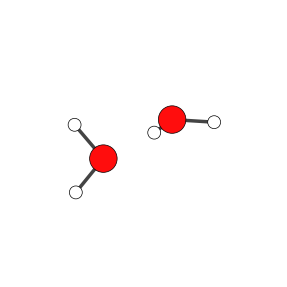

In [4]:
ph.show_molecule(dimer, interactive=INTERACTIVE)

(Set `INTERACTIVE = True` in the first cell and rerun the notebook to rotate the dimer and see the hydrogen bond from any direction.)

The hydrogen bond is almost linear, and the donor O–H bond is slightly **longer** than in the free molecule: the bond is weakened as its hydrogen is shared.

## 2. Basis Set Superposition Error

In the dimer, each monomer can "borrow" the basis functions of its partner to improve its own description. The monomer calculated alone does not get this help. The dimer is therefore artificially stabilized, and the binding energy is **too large**. This is **basis set superposition error** (BSSE).

The **counterpoise** (CP) correction calculates each monomer in the full dimer basis set, with the partner's nuclei and electrons removed but its basis functions left in place as **ghost atoms**.

```{note} Psi4 settings: `bsse_type`
:class: dropdown
`psi4.energy("mp2", molecule=dimer, bsse_type=["cp", "nocp"])`
: Runs the dimer and the monomer calculations automatically and reports the interaction energy both with (`cp`) and without (`nocp`) the counterpoise correction. *Alternative:* `"vmfc"` (valiron-mayer function counterpoise) for clusters of three or more molecules.

The interaction energy is **vertical**: both monomers keep the structure they have in the dimer. The small energy needed to distort them from their free structures (the deformation energy) is not included.
```

In [5]:
psi4.set_options({"g_convergence": "qchem"})
psi4.energy("mp2", molecule=dimer, bsse_type=["cp", "nocp"])

IE_cp = psi4.variable("CP-CORRECTED INTERACTION ENERGY") * h2kJ
IE_nocp = psi4.variable("NOCP-CORRECTED INTERACTION ENERGY") * h2kJ
print(f"Interaction energy without CP: {IE_nocp:6.1f} kJ/mol")
print(f"Interaction energy with CP:    {IE_cp:6.1f} kJ/mol")
print(f"BSSE (overbinding without CP): {IE_cp - IE_nocp:6.1f} kJ/mol")

Interaction energy without CP:  -22.2 kJ/mol
Interaction energy with CP:     -18.7 kJ/mol
BSSE (overbinding without CP):    3.5 kJ/mol


With aug-cc-pVDZ the BSSE is a sizeable fraction of the binding energy. Larger basis sets have less BSSE because each monomer already has plenty of functions of its own. The true answer usually lies between the corrected and uncorrected values for small basis sets, and the two converge as the basis set grows.

## 3. From $D_e$ to $D_0$: Zero-Point Energy

Forming the dimer creates six new low-frequency **intermolecular** vibrations, and each one carries zero-point energy. We calculate the frequencies of the monomer and the dimer (this is the slowest step in the notebook, about two minutes).

In [6]:
psi4.set_options({"g_convergence": "gau_tight"})
E_m, w_mono = psi4.frequency("mp2", molecule=monomer, return_wfn=True)
zpve_mono = psi4.variable("ZPVE")
E_d, w_dimer = psi4.frequency("mp2", molecule=dimer, return_wfn=True)
zpve_dimer = psi4.variable("ZPVE")

print("Dimer frequencies (cm-1):", ", ".join(f"{f:.0f}" for f in w_dimer.frequencies().np))
dZPE = (zpve_dimer - 2 * zpve_mono) * h2kJ
print(f"Change in ZPE on forming the dimer: {dZPE:.1f} kJ/mol")
print(f"D0 ≈ De(CP) - dZPE = {-IE_cp - dZPE:.1f} kJ/mol   (experiment 13.2 kJ/mol)")

Dimer frequencies (cm-1): 128, 148, 151, 184, 358, 639, 1624, 1643, 3704, 3796, 3904, 3925
Change in ZPE on forming the dimer: 8.8 kJ/mol
D0 ≈ De(CP) - dZPE = 9.8 kJ/mol   (experiment 13.2 kJ/mol)


The six lowest frequencies are the new intermolecular modes. The zero-point energy of the dimer is larger than that of two monomers by several kJ/mol, which cancels a large part of the hydrogen-bond energy.

Our $D_0$ is too small for two reasons. First, the CP-corrected MP2/aug-cc-pVDZ interaction energy is a few kJ/mol weaker than the benchmark $D_e$ of 21.0 kJ/mol; larger basis sets fix this. Second, the intermolecular modes are very anharmonic, so the **harmonic** ZPE is too large (*Psi4* warns about this in the output above).

## 4. What Holds the Dimer Together? SAPT

**Symmetry-adapted perturbation theory** (SAPT) calculates the interaction energy directly, as a sum of physically meaningful parts:

- **Electrostatics**: the attraction between the unperturbed charge distributions of the two monomers.
- **Exchange**: the Pauli repulsion when their electron clouds overlap (always positive).
- **Induction**: each molecule polarizing the other (includes charge transfer).
- **Dispersion**: correlated fluctuations of the electrons (London forces).

```{note} Psi4 settings for SAPT
:class: dropdown
`sapt0` with `jun-cc-pvdz`
: SAPT0 is the simplest level of SAPT, and *jun*-cc-pVDZ (aug-cc-pVDZ without the diffuse functions on hydrogen and without diffuse *d* functions) is the recommended "bronze standard" partner because its errors cancel well. *Alternatives:* `sapt2+/aug-cc-pvdz` or `sapt2+(3)dmp2/aug-cc-pvtz` for higher accuracy (much more expensive); `fisapt0` for splitting the interaction into contributions from parts of larger molecules.
```

In [7]:
psi4.set_options({"basis": "jun-cc-pvdz", "g_convergence": "qchem"})
psi4.energy("sapt0", molecule=dimer)

sapt = pd.Series({
    "electrostatics": psi4.variable("SAPT ELST ENERGY"),
    "exchange":       psi4.variable("SAPT EXCH ENERGY"),
    "induction":      psi4.variable("SAPT IND ENERGY"),
    "dispersion":     psi4.variable("SAPT DISP ENERGY"),
    "total":          psi4.variable("SAPT TOTAL ENERGY"),
}) * h2kJ
sapt.round(1).to_frame("kJ/mol")

,kJ/mol
electrostatics,-37.1
exchange,29.5
induction,-9.0
dispersion,-5.3
total,-21.9


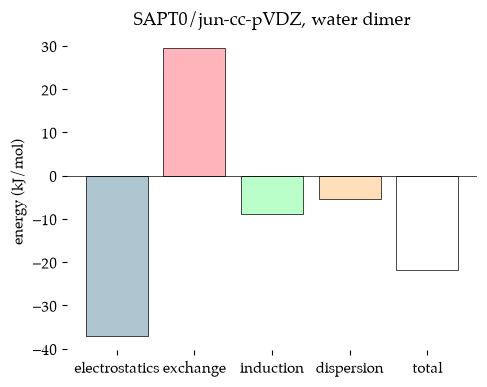

In [8]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(5,4))
colors = ["#AEC6CF", "#FFB3BA", "#BAFFC9", "#FFDFBA", "white"]
ax.bar(sapt.index, sapt.values, color=colors, edgecolor="black", linewidth=0.5)
ax.axhline(0, color="black", linewidth=0.5)
ax.set_ylabel("energy (kJ/mol)")
ax.set_title("SAPT0/jun-cc-pVDZ, water dimer")
plt.show()

**Electrostatics** is the largest attractive term: the hydrogen bond in water is mostly the attraction between the positive hydrogen and the negative lone-pair region that we saw in the *Surfaces* notebook. But exchange repulsion cancels most of it, and induction and dispersion together are needed to give the final binding.

## 5. Which Orbital Accepts the Hydrogen Bond?

The canonical orbitals of the dimer spread over both molecules and are hard to interpret. **Localized** orbitals (see the *Molecular Orbitals* notebook) give bonds and lone pairs. We localize the HF orbitals of the dimer with the Boys method, then find the lone pair on the acceptor oxygen whose centroid lies closest to the bridging hydrogen. The lone pair is drawn with its positive lobe blue and negative lobe red; with `INTERACTIVE = True` you can rotate it to see how it points at the donor hydrogen.

Accepting lone pair: LMO 9
  its centroid is 1.64 Å from the bridging H
  the acceptor O nucleus is 1.95 Å from the bridging H


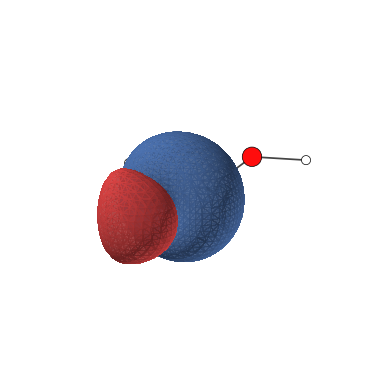

In [9]:
psi4.set_options({"basis": "aug-cc-pvdz", "scf_type": "df"})
E, wfn = psi4.energy("hf", molecule=dimer, return_wfn=True)
loc = psi4.core.Localizer.build("BOYS", wfn.basisset(), wfn.Ca_subset("AO", "OCC"))
loc.localize()
L = loc.L.np

mints = psi4.core.MintsHelper(wfn.basisset())
dip = [m.np for m in mints.ao_dipole()]
centroids = np.array([[-(L[:, i] @ d @ L[:, i]) for d in dip] for i in range(L.shape[1])])

xyz = dimer.geometry().np
H_bridge, O_acceptor = xyz[2], xyz[3]
# lone pairs on the acceptor: centroids close to O(acceptor) but not along its own O-H bonds
dist_to_O = np.linalg.norm(centroids - O_acceptor, axis=1)
dist_to_H = np.linalg.norm(centroids - H_bridge, axis=1)
candidates = [i for i in range(len(centroids)) if 0.2 < dist_to_O[i] < 0.8]
lp = min(candidates, key=lambda i: dist_to_H[i])
b2A = psi4.constants.bohr2angstroms
print(f"Accepting lone pair: LMO {lp + 1}")
print(f"  its centroid is {dist_to_H[lp] * b2A:.2f} Å from the bridging H")
print(f"  the acceptor O nucleus is {np.linalg.norm(O_acceptor - H_bridge) * b2A:.2f} Å from the bridging H")

cube_dir = output_dir / "dimer_cubes"
cube_dir.mkdir(exist_ok=True)
psi4.set_options({"cubeprop_filepath": str(cube_dir)})
psi4.core.CubeProperties(wfn).compute_orbitals(loc.L, [lp], ["acceptor_LP"], "LMO")

ph.show_orbital(next(cube_dir.glob("LMO_*acceptor_LP.cube")), mol=dimer, interactive=INTERACTIVE)

The centroid of the localized lone pair sits about 0.3 Å closer to the bridging hydrogen than the oxygen nucleus does: the lone pair points towards the donor hydrogen. This is the familiar picture of a hydrogen bond as a lone pair reaching towards an O–H bond. But remember from the *Molecular Orbitals* notebook that localized and canonical orbitals describe the same wavefunction: the localized picture does not *cause* the hydrogen bond, it is simply the most convenient way to *see* its direction.

```{tip} Try it
Change `"BOYS"` to `"PIPEK_MEZEY"` and look at the acceptor's lone pairs again. Does the $\sigma$/$\pi$ description of the lone pairs explain the tilted orientation of the acceptor molecule as well as the "rabbit ears" do?
```

```{tip} Going further
- Build a cyclic **water trimer** (each molecule donates one hydrogen bond and accepts one) and compare the binding energy per hydrogen bond with the dimer. Use a smaller basis (`6-31+g*`) for the optimization to keep it fast on *Colab*.
- Repeat the interaction energy with `b3lyp/aug-cc-pvdz`, which has no dispersion, and compare with MP2 and the SAPT dispersion term.
```

## Summary
- Fragments separated by `--` let *Psi4* calculate interaction energies with `bsse_type`.
- Counterpoise correction removes the artificial stabilization from borrowed basis functions.
- Zero-point energy removes a large part of the hydrogen-bond energy ($D_0 < D_e$).
- SAPT shows the water hydrogen bond is mainly electrostatic, with significant induction and dispersion.